<a href="https://colab.research.google.com/github/Pappas313/Computational-vision/blob/main/E_commerce_Sales_Analytics_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Practical Python Data Analytics Project**

Let's build a realistic E-commerce Sales Analytics project using Python and the following libraries:

Library	What we'll use it for
•	Pandas  Data cleaning, filtering, grouping, KPIs
•	NumPy Statistics, calculations, anomaly detection
•	PySpark Processing large datasets and aggregations
•	Xarray  Multidimensional analytics (time × region × product)
•	Matplotlib  Charts, dashboards, visualizations
•	Seaborn Correlation heatmaps and statistical charts
•	Scikit-learn  Predicting future sales with machine learning

**Project scenario**

You work as a Data Analyst for an international e-commerce company. Your company wants to understand sales performance, profitability, customer behavior, and future revenue.

We will generate a realistic synthetic dataset containing 100,000 transactions across four countries, analyze the data, create charts, and build a simple predictive model.

**1. Install the libraries**

Run in your terminal:

In [ ]:

%pip install -q numpy pandas pyarrow pyspark xarray \
    matplotlib seaborn scikit-learn netCDF4


PySpark requires a compatible Java installation.

**2. Generate a realistic dataset — NumPy + Pandas**

We'll generate 100,000 transactions with dates, regions, products, prices, quantities, costs, and customers.

In [1]:

import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
n = 100_000

df = pd.DataFrame({
    "order_id": np.arange(1, n + 1),
    "date": pd.to_datetime("2025-01-01") +
        pd.to_timedelta(rng.integers(0, 365, n), unit="D"),
    "region": rng.choice(
        ["Greece", "Germany", "France", "Italy"], n
    ),
    "category": rng.choice(
        ["Electronics", "Clothing", "Home", "Sports"], n
    ),
    "customer_id": rng.integers(1000, 20000, n),
    "quantity": rng.integers(1, 6, n),
    "unit_price": rng.uniform(10, 500, n).round(2),
    "cost_ratio": rng.uniform(0.4, 0.85, n)
})

df["revenue"] = df["quantity"] * df["unit_price"]
df["cost"] = df["revenue"] * df["cost_ratio"]
df["profit"] = df["revenue"] - df["cost"]

df = df.drop(columns="cost_ratio")

df.to_csv("sales_data.csv", index=False)

print(df.head())
print("Total transactions:", len(df))


   order_id       date   region category  customer_id  quantity  unit_price  \
0         1 2025-02-02   France   Sports         8180         4       46.17   
1         2 2025-10-10    Italy   Sports        17024         3      486.02   
2         3 2025-08-27   France   Sports        17442         5      360.86   
3         4 2025-06-10  Germany   Sports        15328         2      416.56   
4         5 2025-06-08   Greece   Sports        15571         3      250.07   

   revenue        cost      profit  
0   184.68  151.725130   32.954870  
1  1458.06  703.460356  754.599644  
2  1804.30  941.638877  862.661123  
3   833.12  519.348353  313.771647  
4   750.21  626.705830  123.504170  
Total transactions: 100000


Now we have a reusable CSV dataset for the entire project.

**3. Data cleaning and KPIs — Pandas**

Real-world datasets often contain missing values, duplicates, and incorrect data. This is where Pandas becomes especially useful.

In [2]:

import pandas as pd

df = pd.read_csv("sales_data.csv", parse_dates=["date"])

# Remove duplicates
df = df.drop_duplicates(subset="order_id")

# Handle missing values
df = df.dropna(subset=["date", "region", "revenue"])

# Remove invalid transactions
df = df[
    (df["quantity"] > 0) &
    (df["unit_price"] > 0)
].copy()

# Calculate KPIs
total_revenue = df["revenue"].sum()
total_profit = df["profit"].sum()
total_orders = df["order_id"].nunique()
unique_customers = df["customer_id"].nunique()

profit_margin = total_profit / total_revenue * 100

print(f"Revenue: €{total_revenue:,.2f}")
print(f"Profit: €{total_profit:,.2f}")
print(f"Orders: {total_orders:,}")
print(f"Customers: {unique_customers:,}")
print(f"Profit margin: {profit_margin:.2f}%")

# Sales performance by country
regional_sales = df.groupby("region").agg(
    revenue=("revenue", "sum"),
    profit=("profit", "sum"),
    orders=("order_id", "nunique")
).sort_values("revenue", ascending=False)

print(regional_sales)


Revenue: €76,413,582.14
Profit: €28,661,387.79
Orders: 100,000
Customers: 18,914
Profit margin: 37.51%
             revenue        profit  orders
region                                    
Germany  19255067.66  7.213750e+06   25058
Italy    19250663.48  7.249095e+06   24987
France   19052697.16  7.136400e+06   25169
Greece   18855153.84  7.062142e+06   24786


This is the type of code commonly used for business reporting and KPI analysis.

**4. Statistics and anomaly detection — NumPy**

Suppose we want to identify unusually large orders that may indicate high-value customers or unusual transactions.

In [3]:

import numpy as np

revenue = df["revenue"].to_numpy()

mean = np.mean(revenue)
median = np.median(revenue)
std = np.std(revenue)

print("Mean:", mean)
print("Median:", median)
print("Standard deviation:", std)

# Z-score anomaly detection
if std > 0:
    z_scores = (revenue - mean) / std
    anomalies = df[np.abs(z_scores) > 3]
else:
    anomalies = df.iloc[0:0]

print("Unusual transactions:", len(anomalies))

# Revenue percentiles
print("90th percentile:", np.percentile(revenue, 90))
print("99th percentile:", np.percentile(revenue, 99))


Mean: 764.1358214000002
Median: 602.23
Standard deviation: 590.2855017583232
Unusual transactions: 0
90th percentile: 1672.68
99th percentile: 2375.5


**Practical use:** Fraud screening, financial risk analytics, unusual spending detection, and statistical monitoring. A Z-score threshold is only an initial screening rule, not proof of fraud.

**5. Big Data processing — PySpark**

Imagine the company grows from 100,000 transactions to 500 million transactions. Processing the data on a single machine may become difficult.

PySpark enables distributed processing across multiple machines.

In [4]:

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (
    SparkSession.builder
    .appName("EcommerceAnalytics")
    .master("local[*]")
    .getOrCreate()
)

# Read CSV
sales = spark.read.csv(
    "sales_data.csv",
    header=True,
    inferSchema=True
)

# Revenue and profit by region
regional = sales.groupBy("region").agg(
    F.round(F.sum("revenue"), 2).alias("revenue"),
    F.round(F.sum("profit"), 2).alias("profit"),
    F.count("*").alias("transactions")
)

regional.orderBy(
    F.desc("revenue")
).show()

# Monthly revenue
monthly = (
    sales.withColumn(
        "month",
        F.date_format("date", "yyyy-MM")
    )
    .groupBy("month")
    .agg(F.sum("revenue").alias("revenue"))
    .orderBy("month")
)

monthly.show()

# Export aggregated data
monthly.write.mode("overwrite").parquet(
    "monthly_sales.parquet"
)

spark.stop()


+-------+-------------+----------+------------+
| region|      revenue|    profit|transactions|
+-------+-------------+----------+------------+
|Germany|1.925506766E7|7213750.12|       25058|
|  Italy|1.925066348E7|7249095.44|       24987|
| France|1.905269716E7|7136399.85|       25169|
| Greece|1.885515384E7|7062142.37|       24786|
+-------+-------------+----------+------------+

+-------+-----------------+
|  month|          revenue|
+-------+-----------------+
|2025-01|6479480.799999995|
|2025-02|5973144.740000002|
|2025-03|6448592.450000008|
|2025-04|6372522.590000007|
|2025-05|6495816.919999998|
|2025-06|6211035.400000011|
|2025-07|6405519.189999997|
|2025-08|6448262.349999992|
|2025-09|6337112.250000005|
|2025-10|6511323.890000003|
|2025-11|6134239.870000001|
|2025-12|6596531.690000002|
+-------+-----------------+



**Important PySpark concepts for interviews:** DataFrames, lazy evaluation, transformations versus actions, partitions, joins, shuffles, caching, and Parquet.

**6. Multidimensional analytics — Xarray**

Suppose management wants to compare sales across three dimensions:
- Time: 12 months
- Region: 4 countries
- Category: 4 product categories

Xarray is designed for precisely this kind of multidimensional analysis.

In [5]:

import xarray as xr
import pandas as pd

df["month"] = df["date"].dt.to_period("M").dt.to_timestamp()

# Aggregate sales
grouped = df.groupby(
    ["month", "region", "category"]
)["revenue"].sum()

# Convert Pandas data into Xarray
sales_cube = grouped.to_xarray().fillna(0)

print(sales_cube)

# Revenue for Greece
greece = sales_cube.sel(region="Greece")

# Electronics across all countries
electronics = sales_cube.sel(category="Electronics")

# Revenue across all dimensions except month
monthly_revenue = sales_cube.sum(
    dim=["region", "category"]
)

# Best-performing region
region_totals = sales_cube.sum(
    dim=["month", "category"]
)

print("Best region:", region_totals.idxmax().item())
print("Monthly revenue:", monthly_revenue)


<xarray.DataArray 'revenue' (month: 12, region: 4, category: 4)> Size: 2kB
array([[[366319.45, 393787.46, 360659.32, 423898.86],
        [414764.32, 430822.96, 382636.78, 390608.24],
        [394519.76, 418813.46, 401345.29, 385360.59],
        [455094.88, 429159.47, 414031.72, 417658.24]],

       [[369340.01, 376115.11, 381421.54, 348448.87],
        [337891.72, 382142.31, 371946.62, 388769.3 ],
        [392765.8 , 375343.7 , 397758.15, 355723.96],
        [395353.21, 362357.46, 380528.46, 357238.52]],

       [[402930.71, 434768.32, 391963.56, 383500.93],
        [381202.  , 430177.31, 407329.25, 425633.13],
        [387337.44, 419830.16, 408628.65, 372054.68],
        [404746.02, 423447.5 , 394449.08, 380593.71]],

       [[436534.78, 412885.31, 410092.28, 406233.84],
        [425677.16, 371973.79, 399857.53, 396751.57],
        [383486.18, 376341.55, 380491.57, 372247.48],
        [424795.71, 408872.44, 387664.35, 378617.05]],

...

       [[376757.9 , 340948.43, 410322.75, 412217

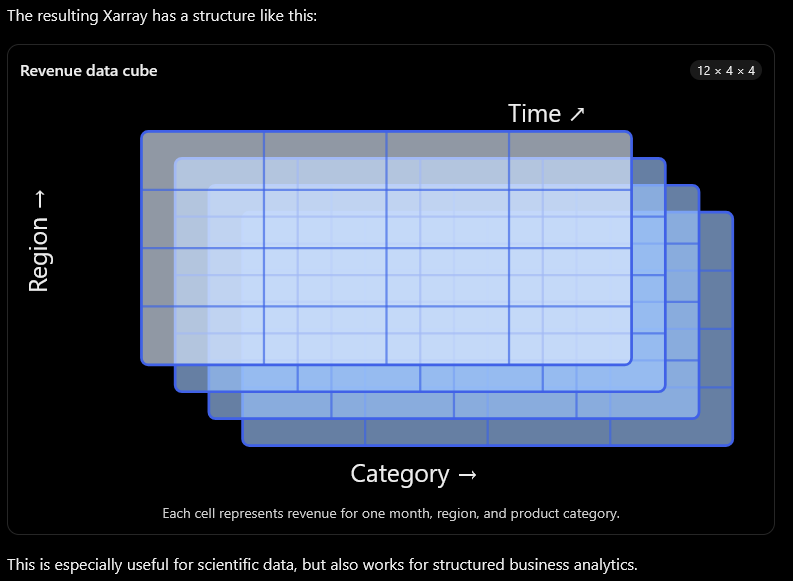![image.png]()

**7. Data visualization — Matplotlib + Seaborn**

Let's build four useful charts: monthly revenue, regional revenue, category profit, and a correlation heatmap.

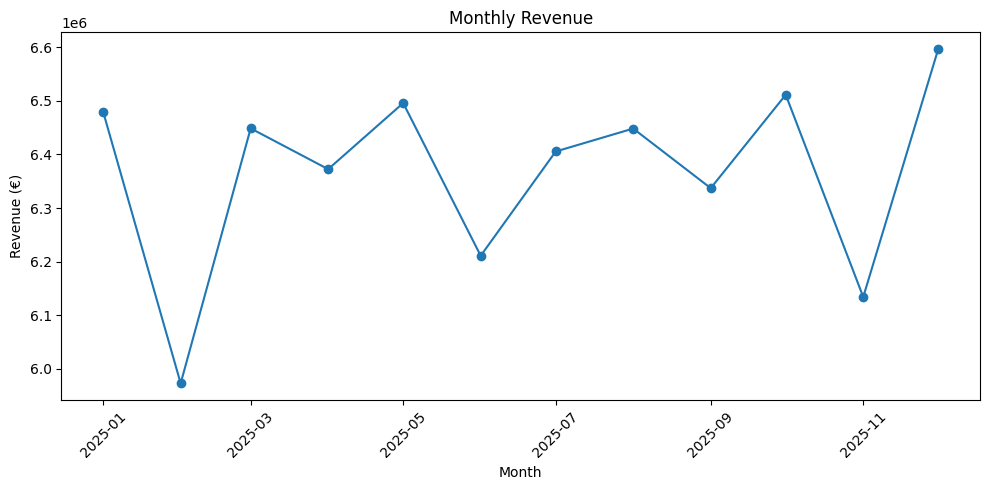

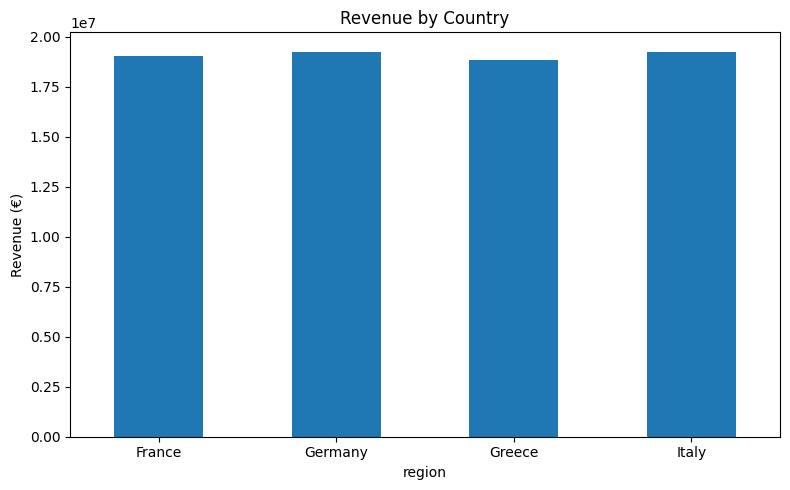

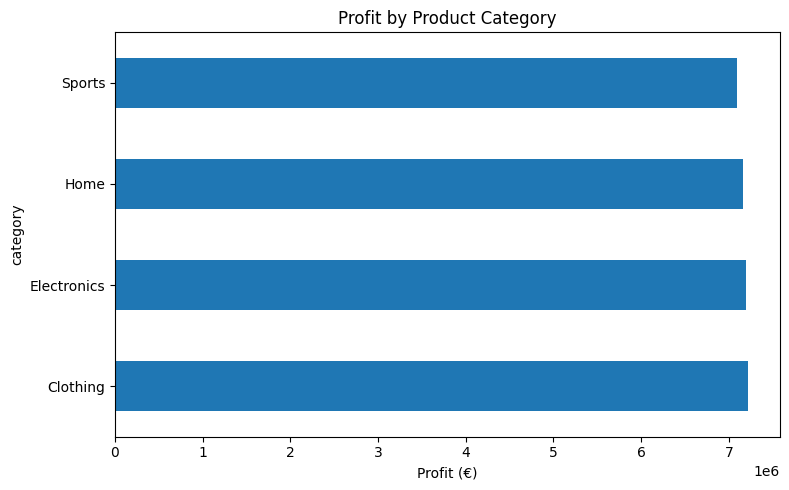

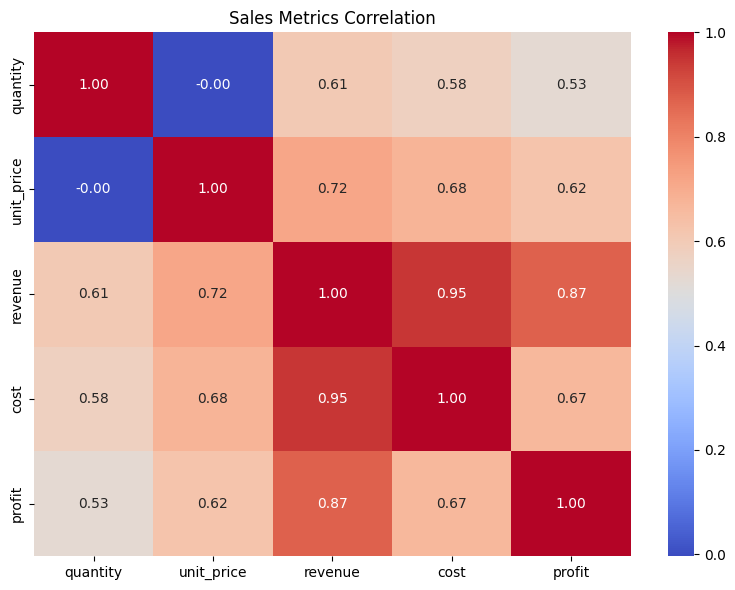

In [6]:

import matplotlib.pyplot as plt
import seaborn as sns

# Monthly revenue
monthly = df.groupby("month")["revenue"].sum()

plt.figure(figsize=(10, 5))
plt.plot(monthly.index, monthly.values, marker="o")
plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (€)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Regional revenue
regional = df.groupby("region")["revenue"].sum()

plt.figure(figsize=(8, 5))
regional.plot(kind="bar")
plt.title("Revenue by Country")
plt.ylabel("Revenue (€)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Profit by category
category_profit = df.groupby("category")["profit"].sum()

plt.figure(figsize=(8, 5))
category_profit.plot(kind="barh")
plt.title("Profit by Product Category")
plt.xlabel("Profit (€)")
plt.tight_layout()
plt.show()

# Correlation heatmap
columns = ["quantity", "unit_price", "revenue", "cost", "profit"]

plt.figure(figsize=(8, 6))
sns.heatmap(
    df[columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Sales Metrics Correlation")
plt.tight_layout()
plt.show()


**8. Machine learning — Scikit-learn**

Now we want to predict monthly revenue using historical monthly sales.


This is a simple baseline model, not a production-ready forecasting system.

In [7]:

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

monthly = (
    df.groupby("month")["revenue"]
    .sum()
    .sort_index()
    .reset_index()
)

monthly["month_index"] = np.arange(len(monthly))

# Chronological split: first 9 months train,
# last 3 months test
train = monthly.iloc[:9]
test = monthly.iloc[9:]

model = LinearRegression()

model.fit(
    train[["month_index"]],
    train["revenue"]
)

predictions = model.predict(
    test[["month_index"]]
)

mae = mean_absolute_error(
    test["revenue"],
    predictions
)

print(f"Test MAE: €{mae:,.2f}")

# Forecast next month
next_index = pd.DataFrame({
    "month_index": [len(monthly)]
})

forecast = model.predict(next_index)[0]

print(f"Next month forecast: €{forecast:,.2f}")


Test MAE: €186,801.27
Next month forecast: €6,433,486.73


Because this example uses randomly generated transactions with approximately uniform monthly activity, it does not contain a strong underlying growth trend. The forecast is mainly a demonstration of the ML workflow.

**9. Putting everything together — Data Analytics pipeline**

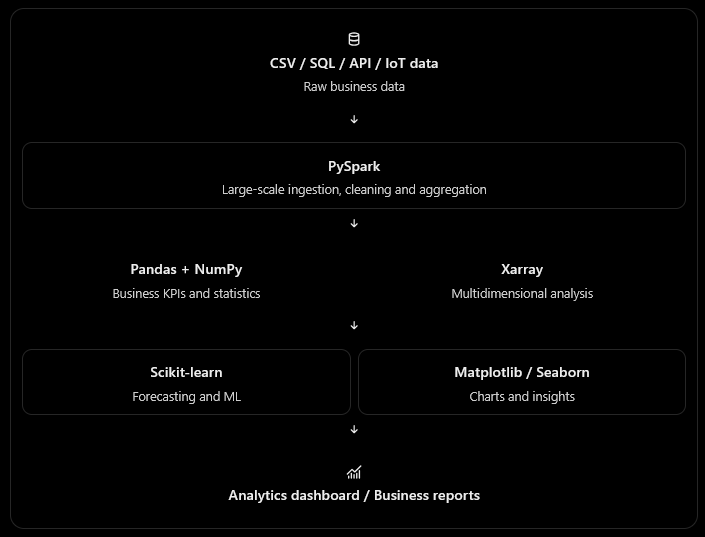

**10. Recommended project structure**

ecommerce-analytics/

│

├── data/

│   └── sales_data.csv

│

├── notebooks/

│   └── exploratory_analysis.ipynb

│

├── src/

│   ├── generate_data.py

│   ├── clean_data.py

│   ├── spark_processing.py

│   ├── statistical_analysis.py

│   ├── xarray_analysis.py

│   ├── visualizations.py

│   └── forecasting.py

│

├── output/

│   ├── monthly_sales.parquet

│   └── charts/

│

└── requirements.txt